In [1]:
import pandas as pd
import matplotlib as pyplot
import seaborn as sns

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [4]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='str')

# Handle Missing Values

In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [6]:
df["Income"]=df["Income"].fillna(df["Income"].median())

In [7]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

# Feature Engineering

In [8]:
# f1 : Age column
df["Age"] = 2026 - df["Year_Birth"]

In [9]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

reference_data = df["Dt_Customer"].max()

df["Days_of_joining"] = (reference_data - df["Dt_Customer"]).dt.days

In [10]:
print(df["Dt_Customer"].head())
print(df["Dt_Customer"].dtype)

0   2012-09-04
1   2014-03-08
2   2013-08-21
3   2014-02-10
4   2014-01-19
Name: Dt_Customer, dtype: datetime64[us]
datetime64[us]


In [11]:
# Spending
df["Total_Spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntGoldProds"] + df["MntSweetProducts"]

In [12]:
# Children
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [13]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [14]:
df["Living_With"] = df["Marital_Status"].replace ({
    "Married" : "Partner", "Together":"Partner",
    "Single" : "Alone", "Divorced": "Alone", "Widow ": "Alone", "Absurd":"Alone", "YOLO": "Alone"
})

In [15]:
df.Education.value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [16]:
df["Education"] = df["Education"].replace ({
    "2n Cycle" : "Undergraduate", "Basic":"Undergraduate",
    "Graduation" : "Graduate", "Master": "PostGraduate",
    "PhD": "PostGraduate", "Basic ": "PostGraduate"
})

# Drop Columns

In [17]:
cols = ['ID', 'Year_Birth','Marital_Status','Kidhome',
       'Teenhome', 'Dt_Customer']

Spending_cols = ['MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds']

cols_to_drop = cols + Spending_cols

df_cleaned = df.drop(columns=cols_to_drop)

In [18]:
df_cleaned.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age', 'Days_of_joining',
       'Total_Spending', 'Total_Children', 'Living_With'],
      dtype='str')

# Outliers

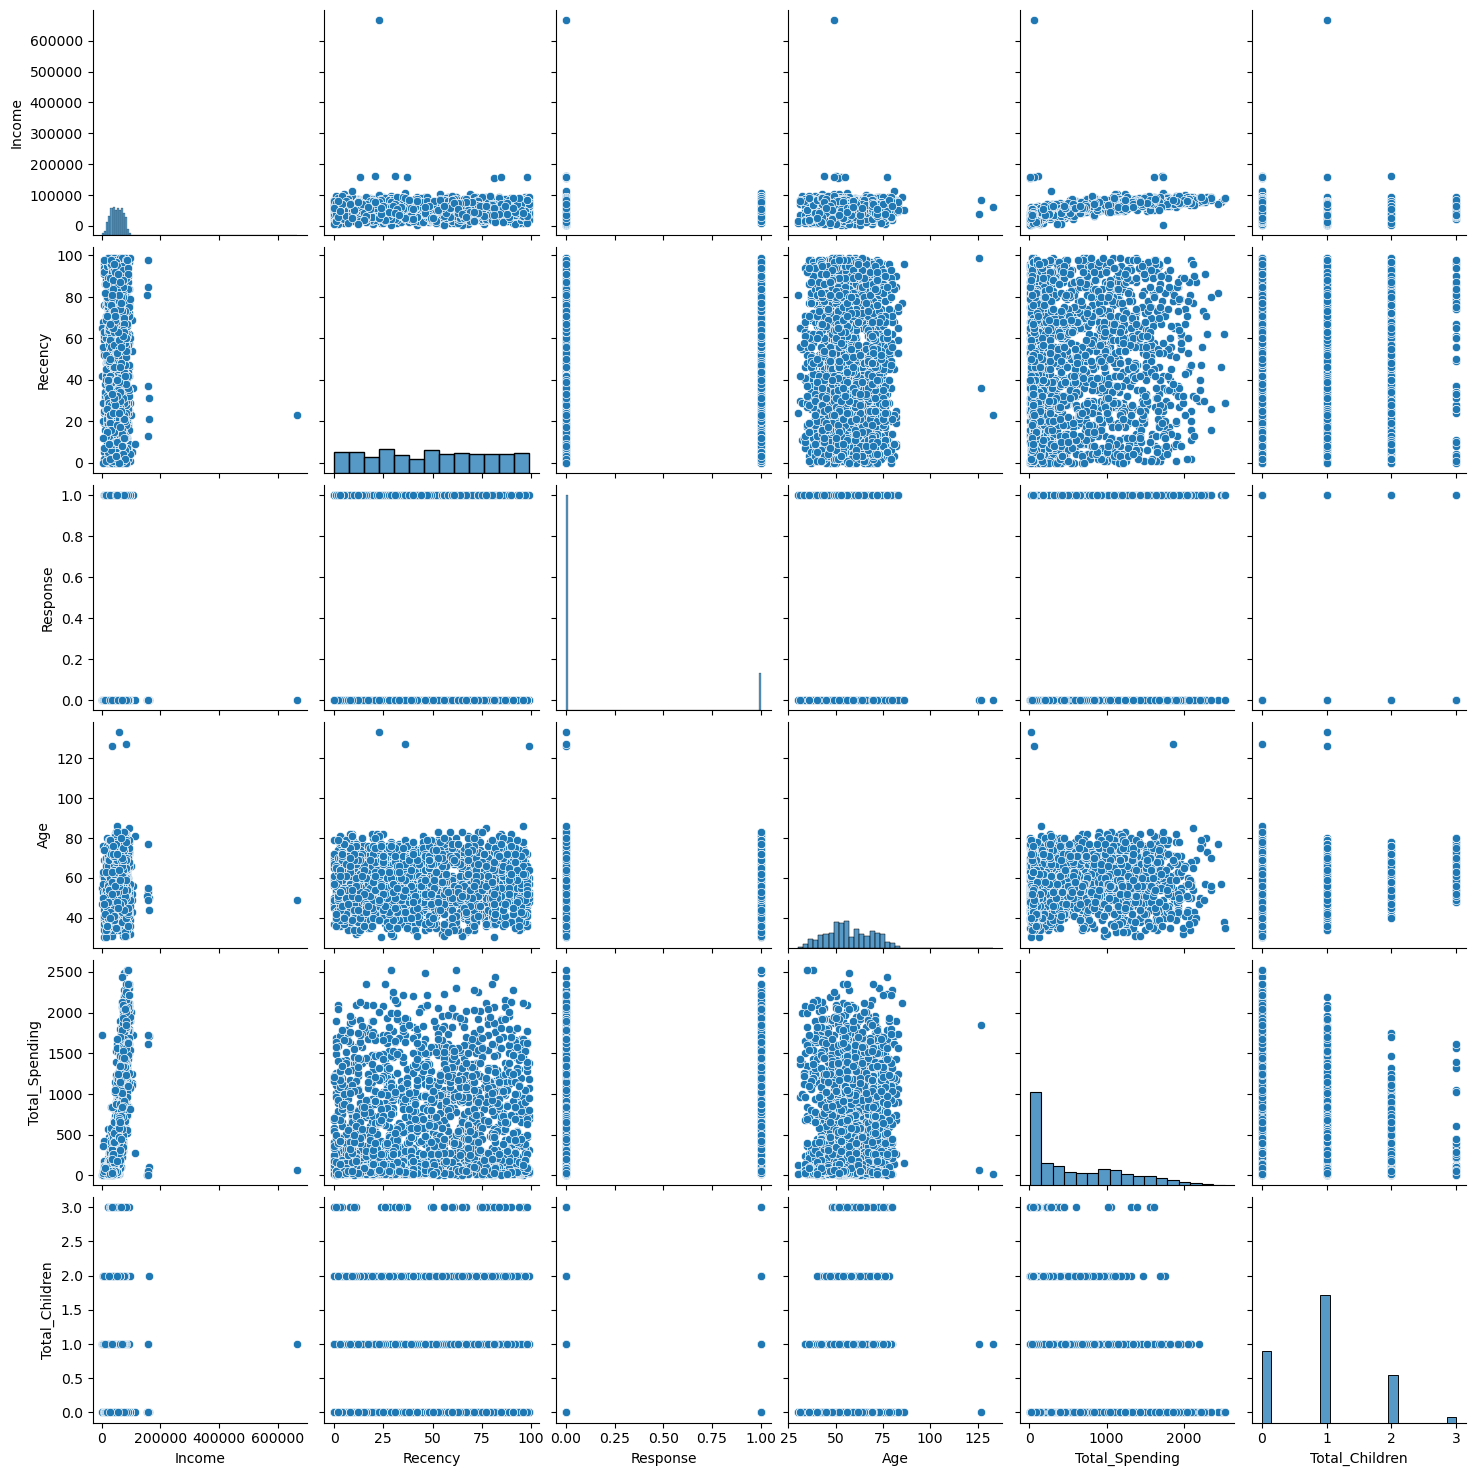

In [19]:
# pair plot
cols = ['Income', 'Recency', 'Response', 'Age','Total_Spending', 'Total_Children']
sns.pairplot(df_cleaned[cols])

In [20]:
# Handle Outliers

print("size of data with outliers : ", len(df_cleaned))

df_cleaned = df_cleaned [ df_cleaned ["Age"] < 90 ]
df_cleaned = df_cleaned [ df_cleaned ["Income"] < 600_000 ]

print("size of data without outliers : ", len(df_cleaned))

size of data with outliers :  2240
size of data without outliers :  2236


# HeatMap

In [21]:
correlation = df_cleaned.corr(numeric_only = True)

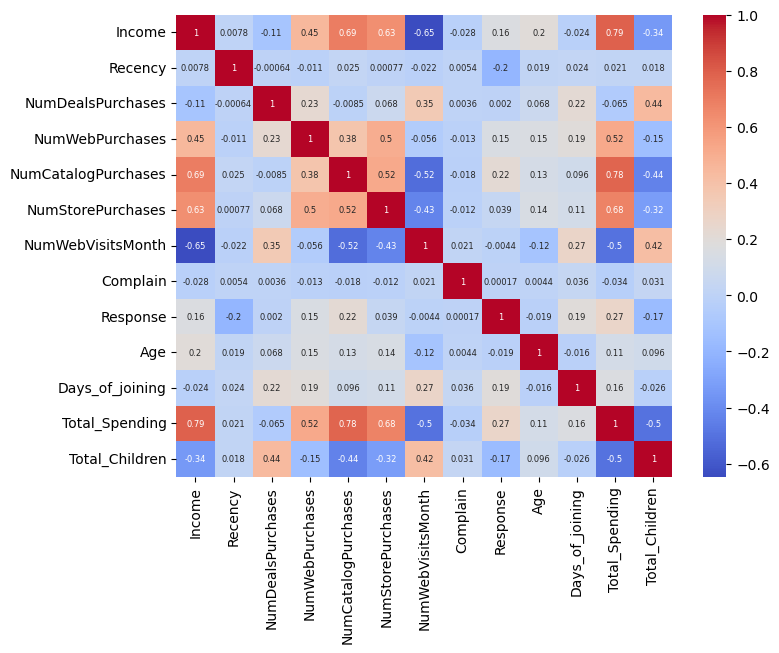

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize = (8, 6))

sns.heatmap (correlation, annot = True, cmap = "coolwarm", annot_kws= {"size": 6})

plt.show()

# Encoding

In [23]:
# One Hot Encoder
from sklearn.preprocessing import OneHotEncoder

Ohe = OneHotEncoder()

cat_cols = ["Education", "Living_With" ]

enc_cols = Ohe.fit_transform(df_cleaned[cat_cols])

In [24]:
enc_df = pd.DataFrame(
    enc_cols.toarray(),
    columns=Ohe.get_feature_names_out(cat_cols),
    index=df_cleaned.index
)

In [25]:
encoded_df = pd.concat(
    [df_cleaned.drop(columns=cat_cols), enc_df],
    axis=1
)

In [26]:
encoded_df.shape

(2236, 19)

# Scaled

In [27]:
from sklearn.preprocessing import StandardScaler

X = encoded_df

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X) 

# Visualize

In [28]:
X_scaled.shape

(2236, 19)

In [29]:
from sklearn.decomposition import PCA

In [30]:
pca = PCA(n_components = 3)

X_pca = pca.fit_transform(X_scaled)

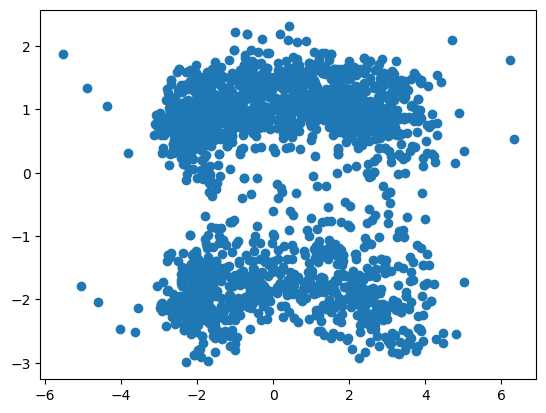

In [31]:
# plot 
plt.scatter(X_pca[:, 0], X_pca[:,1])

In [32]:
pca.explained_variance_ratio_

array([0.21962796, 0.10496607, 0.09875788])

Text(0.5, 0.92, '3d PCA')

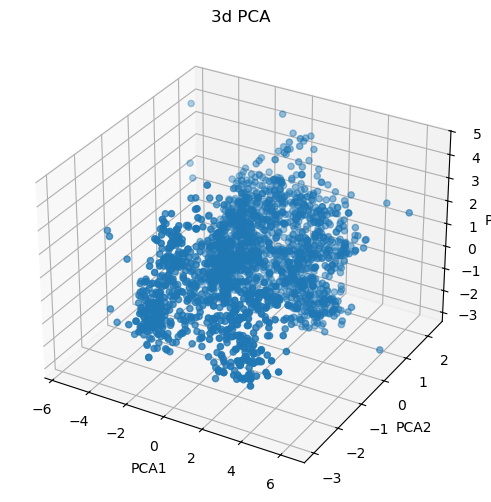

In [33]:
#plot
fig = plt.figure(figsize = (8, 6))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:, 0], X_pca[:,1], X_pca[:,2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3d PCA")

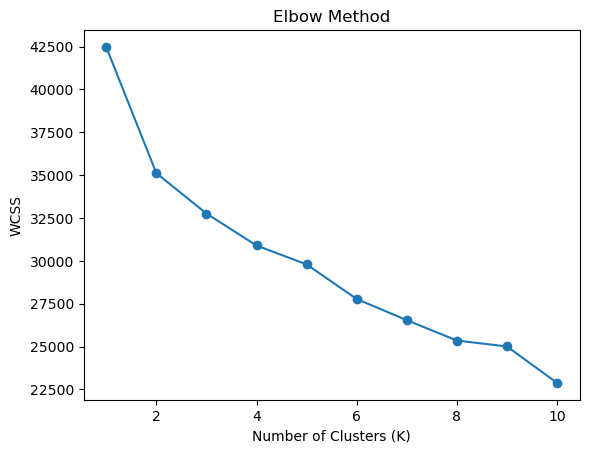

In [34]:
# Elbow 
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

Text(0, 0.5, 'Silhouette score')

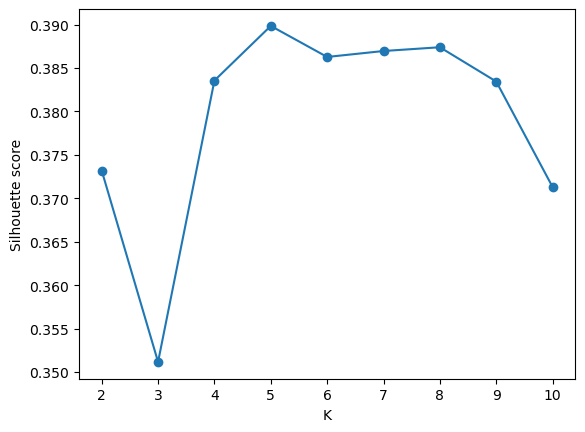

In [35]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    scores.append(score)

# plot
plt.plot(range(2, 11), scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette score")

Text(0, 0.5, 'SS')

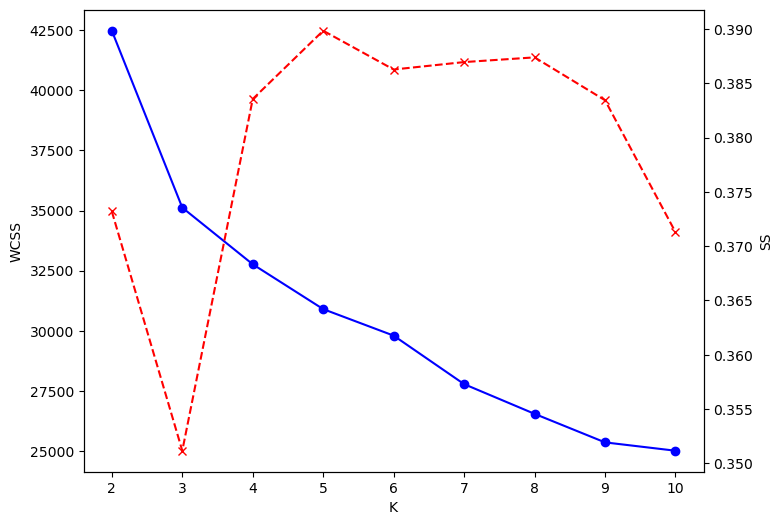

In [36]:
# combined plot

k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(k_range, wcss[:len(k_range)], marker="o", color="blue") 
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker="x", color="red", linestyle="--")
ax2.set_ylabel("SS")

# Clustering

In [37]:
# K_means

kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(X_pca)

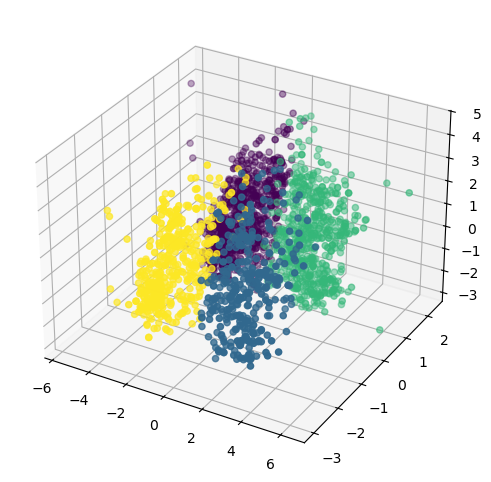

In [38]:
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels_kmeans)

In [39]:
# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

In [40]:
agg_clf = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg_clf.fit_predict(X_pca)

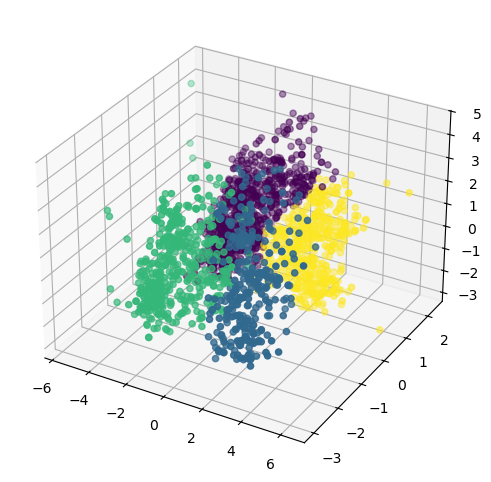

In [41]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels_agg)

# Characterization 

In [42]:
X["cluster"] = labels_agg

In [43]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Days_of_joining,Total_Spending,Total_Children,Education_Graduate,Education_PostGraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,Living_With_Widow,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,0.0,1
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,0.0,3
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0.0,0


<Axes: xlabel='cluster', ylabel='count'>

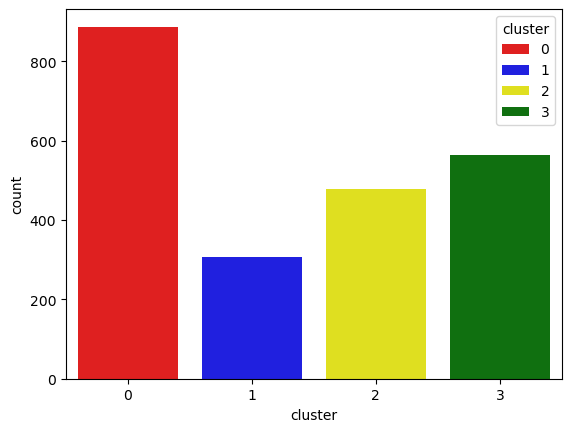

In [44]:
pal = ["red", "blue", "yellow", "green"]

sns.countplot(x=X["cluster"], palette=pal, hue=X["cluster"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

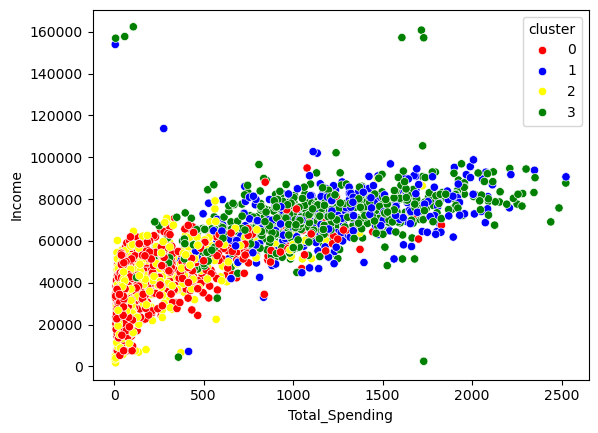

In [45]:
sns.scatterplot(x=X["Total_Spending"], y=X["Income"], hue=X["cluster"], palette=pal)

In [47]:
# CLUSTER SUMMARY
cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39469.949267  49.322435           2.678692         3.155581   
1        71645.185668  51.280130           1.814332         5.798046   
2        39157.029289  47.834728           2.587866         3.004184   
3        71709.340426  48.700355           1.828014         5.540780   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   1.021421           4.148816           6.473506  0.007892   
1                   5.289902           8.482085           3.560261  0.006515   
2                   1.016736           4.010460           6.552301  0.010460   
3                   5.210993           8.436170           3.414894  0.010638   

         Response        Age  Days_of_joining  Total_Spending  Total_Children  \
clust